# How Much Cheaper Is a Damaged Car, Really?

**Dataset:** 50,000 used car listings scraped from eBay Kleinanzeigen (the German classifieds site), crawled March and April 2016.

---

## The question

The brief asks: **how much cheaper are cars with unrepaired damage than their undamaged counterparts?**

The obvious approach is to compare the two groups' average prices. Doing that gives a **76% discount**, which is implausibly large and should not be believed, because damaged cars are not otherwise identical to undamaged ones. They are older and have more miles on them, and a naive comparison charges damage for all of that too.

This notebook separates the damage effect from the confounds, and along the way finds **1,000 listings that are physically impossible** and were quietly distorting the answer.

## 1. Loading and the data quality audit

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

autos = pd.read_csv("autos.csv", encoding="Latin-1")

# price and odometer arrive as strings: "$5,000" and "150,000km".
autos["price_eur"] = (autos["price"].str.replace("$", "", regex=False)
                      .str.replace(",", "", regex=False).astype(int))
autos["odometer_km"] = (autos["odometer"].str.replace("km", "", regex=False)
                        .str.replace(",", "", regex=False).astype(int))

print("rows, columns:", autos.shape)
print()
print("PRICE")
p = autos["price_eur"]
print("  min %d, max %d" % (p.min(), p.max()))
print("  exactly 0:      %d (%.1f%%)" % ((p == 0).sum(), 100 * (p == 0).mean()))
print("  at or above 1m: %d" % (p >= 1e6).sum())
print("  largest values:", sorted(p.unique())[-6:])
print("  (11111111 and 12345678 are keyboard mashing, not prices)")
print()
print("REGISTRATION YEAR")
y = autos["yearOfRegistration"]
print("  min %d, max %d" % (y.min(), y.max()))
print("  before 1900: %d     after 2016: %d" % ((y < 1900).sum(), (y > 2016).sum()))
print("  (the data was crawled in March and April 2016)")
print()
print("COLUMNS THAT CARRY NO INFORMATION")
for col in ["seller", "offerType", "nrOfPictures"]:
    vc = autos[col].value_counts()
    print("  %-13s %s" % (col, dict(list(vc.items())[:3])))
print()
print("ODOMETER is banded, not continuous, and top-coded:")
print(" ", sorted(autos["odometer_km"].unique()))
print("  %.1f%% of all listings sit on the 150,000 km cap" %
      (100 * (autos["odometer_km"] == 150000).mean()))
print()
print("DAMAGE FIELD")
print(" ", autos["notRepairedDamage"].value_counts(dropna=False).to_dict())
print("  (ja = unrepaired damage, nein = none, blank = %.1f%% of listings)" %
      (100 * autos["notRepairedDamage"].isna().mean()))

rows, columns: (50000, 22)

PRICE
  min 0, max 99999999
  exactly 0:      1421 (2.8%)
  at or above 1m: 11
  largest values: [np.int64(3890000), np.int64(10000000), np.int64(11111111), np.int64(12345678), np.int64(27322222), np.int64(99999999)]
  (11111111 and 12345678 are keyboard mashing, not prices)

REGISTRATION YEAR
  min 1000, max 9999
  before 1900: 6     after 2016: 1966
  (the data was crawled in March and April 2016)

COLUMNS THAT CARRY NO INFORMATION
  seller        {'privat': 49999, 'gewerblich': 1}
  offerType     {'Angebot': 49999, 'Gesuch': 1}
  nrOfPictures  {0: 50000}

ODOMETER is banded, not continuous, and top-coded:
  [np.int64(5000), np.int64(10000), np.int64(20000), np.int64(30000), np.int64(40000), np.int64(50000), np.int64(60000), np.int64(70000), np.int64(80000), np.int64(90000), np.int64(100000), np.int64(125000), np.int64(150000)]
  64.8% of all listings sit on the 150,000 km cap

DAMAGE FIELD
  {'nein': 35232, nan: 9829, 'ja': 4939}
  (ja = unrepaired damage

In [2]:
# Keep plausible listings. Prices below EUR 100 are placeholders and giveaways;
# above EUR 150,000 is outside the used-classifieds market this data describes.
cars = autos[(autos["price_eur"] >= 100) & (autos["price_eur"] <= 150000) &
             (autos["yearOfRegistration"] >= 1950) &
             (autos["yearOfRegistration"] <= 2016)].copy()
cars["age"] = 2016 - cars["yearOfRegistration"]

print("kept %d of %d listings (%.1f%% dropped)" %
      (len(cars), len(autos), 100 * (1 - len(cars) / len(autos))))

kept 46315 of 50000 listings (7.4% dropped)


## 2. The naive answer, and why the groups are not comparable

In [3]:
damaged = cars[cars["notRepairedDamage"] == "ja"]
undamaged = cars[cars["notRepairedDamage"] == "nein"]
blank = cars[cars["notRepairedDamage"].isna()]

print("NAIVE COMPARISON")
print("  undamaged: mean EUR %5.0f, median EUR %5.0f  (n=%d)" %
      (undamaged["price_eur"].mean(), undamaged["price_eur"].median(), len(undamaged)))
print("  damaged:   mean EUR %5.0f, median EUR %5.0f  (n=%d)" %
      (damaged["price_eur"].mean(), damaged["price_eur"].median(), len(damaged)))
print("  discount: %.1f%% on means, %.1f%% on medians" % (
      100 * (1 - damaged["price_eur"].mean() / undamaged["price_eur"].mean()),
      100 * (1 - damaged["price_eur"].median() / undamaged["price_eur"].median())))
print()
print("ARE THE GROUPS OTHERWISE ALIKE?")
print("  %-10s %7s %9s %10s %12s" % ("group", "n", "mean age", "mean km", "% at 150k cap"))
for label, g in [("undamaged", undamaged), ("damaged", damaged), ("blank", blank)]:
    print("  %-10s %7d %9.1f %10.0f %11.1f%%" % (
          label, len(g), g["age"].mean(), g["odometer_km"].mean(),
          100 * (g["odometer_km"] == 150000).mean()))

NAIVE COMPARISON
  undamaged: mean EUR  7057, median EUR  4199  (n=33747)
  damaged:   mean EUR  2251, median EUR  1000  (n=4476)
  discount: 68.1% on means, 76.2% on medians

ARE THE GROUPS OTHERWISE ALIKE?
  group            n  mean age    mean km % at 150k cap
  undamaged    33747      12.3     122974        60.3%
  damaged       4476      15.0     135500        76.9%
  blank         8092      15.0     132255        75.4%


**They are not alike at all.** Damaged cars average 15.0 years old against 12.3 for undamaged, and 77% of them sit on the mileage cap against 60%. Age and mileage are the two biggest drivers of a used car price, so the naive 76% is measuring damage, age and mileage together.

Note the third row too. The **8,092 listings with the damage field left blank** are nearly identical to the damaged group on age (15.0 against 15.0) and on the mileage cap (75.4% against 76.9%). They do not look like a random sample of the market, which matters for how they are handled later.

## 3. A first attempt by age band, and the result that refused to make sense

Splitting by age band is the obvious first control. It produced one figure that could not possibly be right, which turned out to be the most useful thing in the notebook.

In [4]:
AGE_BINS = [-1, 3, 6, 9, 12, 15, 20, 100]
AGE_LABELS = ["0-3", "4-6", "7-9", "10-12", "13-15", "16-20", "21+"]

def discount_by_age(df, note):
    k = df[df["notRepairedDamage"].notna()].copy()
    k["damaged"] = k["notRepairedDamage"] == "ja"
    k["age_band"] = pd.cut(k["age"], AGE_BINS, labels=AGE_LABELS)
    rows = []
    for band, g in k.groupby("age_band", observed=True):
        nd, dd = g[~g["damaged"]], g[g["damaged"]]
        if len(dd) < 20:
            continue
        rows.append({"age_band": band, "n_undamaged": len(nd), "n_damaged": len(dd),
                     "median_undamaged": nd["price_eur"].median(),
                     "median_damaged": dd["price_eur"].median(),
                     "discount_pct": round(100 * (1 - dd["price_eur"].median() / nd["price_eur"].median()), 1)})
    out = pd.DataFrame(rows)
    print(note)
    print(out.to_string(index=False))
    return out

first_pass = discount_by_age(cars, "Discount within age band, first pass:")
print()
print("The 0-3 band says a near-new car with damage sells for EUR 950 against")
print("EUR 16,250 undamaged: a 94% discount. That is not a market price, so")
print("something is wrong with those 200 listings.")

Discount within age band, first pass:
age_band  n_undamaged  n_damaged  median_undamaged  median_damaged  discount_pct
     0-3         2189        200           16250.0           949.5          94.2
     4-6         4068        156           12790.0          7949.5          37.8
     7-9         5594        372            7900.0          4600.0          41.8
   10-12         6388        669            4778.5          2600.0          45.6
   13-15         5645        880            2550.0          1100.0          56.9
   16-20         7197       1603            1350.0           600.0          55.6
     21+         2666        596            1800.0           600.0          66.7

The 0-3 band says a near-new car with damage sells for EUR 950 against
EUR 16,250 undamaged: a 94% discount. That is not a market price, so
something is wrong with those 200 listings.


In [5]:
# Investigating the 200 listings behind that 94% figure.
suspect = cars[(cars["notRepairedDamage"] == "ja") & (cars["age"] <= 3)]

print("damaged cars aged 0-3: n=%d, median price EUR %.0f" %
      (len(suspect), suspect["price_eur"].median()))
print()
print("registration year:", suspect["yearOfRegistration"].value_counts().sort_index().to_dict())
print("  -> %d of %d claim 2016, the year of the crawl" %
      ((suspect["yearOfRegistration"] == 2016).sum(), len(suspect)))
print()
print("at the 150,000 km cap: %d of %d" %
      ((suspect["odometer_km"] == 150000).sum(), len(suspect)))
print("  -> a car registered in 2016 and crawled in March 2016 cannot have 150,000 km")
print()
print("what the cheapest listings call themselves:")
for name, price, year, km in suspect.nsmallest(8, "price_eur")[
        ["name", "price_eur", "yearOfRegistration", "odometer_km"]].values:
    print("   %-50s EUR %5d  %d  %6d km" % (str(name)[:50], price, year, km))

damaged cars aged 0-3: n=200, median price EUR 950

registration year: {2013: 21, 2014: 20, 2015: 7, 2016: 152}
  -> 152 of 200 claim 2016, the year of the crawl

at the 150,000 km cap: 131 of 200
  -> a car registered in 2016 and crawled in March 2016 cannot have 150,000 km

what the cheapest listings call themselves:
   Fahre_oder_Nimm_mich_aus                           EUR   100  2016  150000 km
   Kombi_mit_brauchbaren_Reifen____2_Winterreifen_neu EUR   100  2016  150000 km
   Verkaufe_einen_Golf_2_zum_Ausschlachten_mit_Gewind EUR   100  2016  150000 km
   Verkaufe_Polo_1.3__6N1_                            EUR   150  2016  150000 km
   Ford_Fiesta_Sport_fuer_Bastler                     EUR   150  2016  150000 km
   Bastlerfahrzeug_mit_Rest_Tuev                      EUR   150  2016  150000 km
   Opel_Corsa_SWING___JOY_Benziner_mit_Erdgas_Anlage  EUR   150  2016  150000 km
   Renault_Megane__springt_nicht_an__Batterie_tot?    EUR   150  2016  150000 km


**These are scrap and parts cars with a placeholder registration year.**

The German gives it away. *Bastlerfahrzeug* is a project car for a hobbyist. *zum Ausschlachten* means for stripping. *springt nicht an* means it will not start. One listing is called *Fahre oder Nimm mich aus*: drive me or strip me. And a "Golf 2" is a model built between 1983 and 1992, listed here with a registration year of 2016.

Sellers who did not fill in the registration year got **2016** by default, which the data then reads as a brand new car. Combined with the 150,000 km cap, it produces a fleet of imaginary near-new wrecks.

The test is simple and does not require any judgement about listing text: **a car registered in 2016 and crawled in March 2016 cannot have driven 125,000 km.** That combination is physically impossible.

In [6]:
impossible = (cars["yearOfRegistration"] == 2016) & (cars["odometer_km"] >= 125000)

print("listings registered 2016 with at least 125,000 km: %d" % impossible.sum())
print("  median price: EUR %.0f" % cars[impossible]["price_eur"].median())
print("  damage field: ja %d, nein %d, blank %d" % (
      (cars[impossible]["notRepairedDamage"] == "ja").sum(),
      (cars[impossible]["notRepairedDamage"] == "nein").sum(),
      cars[impossible]["notRepairedDamage"].isna().sum()))
print("  blank rate here: %.1f%%, against %.1f%% across all listings" % (
      100 * cars[impossible]["notRepairedDamage"].isna().mean(),
      100 * cars["notRepairedDamage"].isna().mean()))
print()
print("Blanks are nearly three times as common in this junk, which is more")
print("evidence that a missing damage field signals an unserious listing.")
print()

clean = cars[~impossible].copy()
second_pass = discount_by_age(clean, "Discount within age band, after removing them:")
print()
print("The 0-3 band moves from 94.2%% to 58.9%%, which is a price rather than an artifact.")

listings registered 2016 with at least 125,000 km: 1000
  median price: EUR 999
  damage field: ja 135, nein 384, blank 481
  blank rate here: 48.1%, against 17.5% across all listings

Blanks are nearly three times as common in this junk, which is more
evidence that a missing damage field signals an unserious listing.

Discount within age band, after removing them:
age_band  n_undamaged  n_damaged  median_undamaged  median_damaged  discount_pct
     0-3         1805         65           18900.0          7777.0          58.9
     4-6         4068        156           12790.0          7949.5          37.8
     7-9         5594        372            7900.0          4600.0          41.8
   10-12         6388        669            4778.5          2600.0          45.6
   13-15         5645        880            2550.0          1100.0          56.9
   16-20         7197       1603            1350.0           600.0          55.6
     21+         2666        596            1800.0           600.

## 4. Matching like with like

Age bands alone still compare a damaged BMW against an undamaged Golf. The stronger approach is to compare only cars that match on **brand, model, age band and odometer reading**, requiring at least five listings on each side of a cell so the medians mean something.

Odometer is already banded into 13 values, which makes exact matching on mileage possible rather than approximate.

In [7]:
matched = clean[clean["notRepairedDamage"].notna()].copy()
matched["damaged"] = matched["notRepairedDamage"] == "ja"
matched["age_band"] = pd.cut(matched["age"], AGE_BINS, labels=AGE_LABELS)

MIN_PER_SIDE = 5
cells = []
for key, g in matched.groupby(["brand", "model", "age_band", "odometer_km"], observed=True):
    nd, dd = g[~g["damaged"]], g[g["damaged"]]
    if len(nd) >= MIN_PER_SIDE and len(dd) >= MIN_PER_SIDE:
        cells.append({
            "brand": key[0], "model": key[1], "age_band": str(key[2]), "km": key[3],
            "n_undamaged": len(nd), "n_damaged": len(dd),
            "median_undamaged": nd["price_eur"].median(),
            "median_damaged": dd["price_eur"].median(),
        })

cells = pd.DataFrame(cells)
cells["discount_pct"] = 100 * (1 - cells["median_damaged"] / cells["median_undamaged"])

print("matched cells: %d" % len(cells))
print("covering %d undamaged and %d damaged listings" %
      (cells["n_undamaged"].sum(), cells["n_damaged"].sum()))
print()
print("WITHIN-CELL DAMAGE DISCOUNT")
print("  weighted by damaged listings: %.1f%%" %
      np.average(cells["discount_pct"], weights=cells["n_damaged"]))
print("  unweighted mean of cells:     %.1f%%" % cells["discount_pct"].mean())
print("  median of cells:              %.1f%%" % cells["discount_pct"].median())
print("  interquartile range:          %.1f%% to %.1f%%" %
      (cells["discount_pct"].quantile(0.25), cells["discount_pct"].quantile(0.75)))
print()
print("against a naive median-based discount of 76.2%")
print()
print("widest and narrowest cells:")
show = cells.sort_values("discount_pct")
cols = ["brand", "model", "age_band", "km", "n_undamaged", "n_damaged",
        "median_undamaged", "median_damaged", "discount_pct"]
print(pd.concat([show.head(3), show.tail(3)])[cols].round(1).to_string(index=False))

matched cells: 176
covering 13550 undamaged and 2456 damaged listings

WITHIN-CELL DAMAGE DISCOUNT
  weighted by damaged listings: 44.4%
  unweighted mean of cells:     42.6%
  median of cells:              44.4%
  interquartile range:          33.3% to 52.9%

against a naive median-based discount of 76.2%

widest and narrowest cells:
  brand   model age_band     km  n_undamaged  n_damaged  median_undamaged  median_damaged  discount_pct
 nissan primera    16-20 150000           20          6             920.0           970.0          -5.4
peugeot 4_reihe    16-20 150000            5          8             800.0           775.0           3.1
    bmw     1er    10-12 150000           60         10            6050.0          5524.5           8.7
   opel   omega      21+ 150000           15          5             750.0           220.0          70.7
   ford      ka    16-20 125000           17          6             780.0           210.0          73.1
 nissan  andere      21+ 150000        

**Matched on brand, model, age band and mileage, the damage discount is about 44%, not 76%.**

Roughly **32 percentage points**, which is 42% of the apparent discount, was age and mileage being charged to damage.

44% is still a large number, and it should be. A buyer taking on unrepaired damage is accepting an unknown repair bill, a failed roadworthiness test, and a car that is harder to resell. But it is a price, not an artifact, and it is the number a seller could actually use.

The interquartile range of 33% to 53% across cells is worth noting too: the discount is not one fixed figure, and it varies with what the car is.

**Matched on brand, model, age band and mileage, the damage discount is about 44%, not 76%.**

Roughly **32 percentage points**, which is 42% of the apparent discount, was age and mileage being charged to damage.

44% is still large, and it should be. A buyer taking on unrepaired damage is accepting an unknown repair bill, a probable failed roadworthiness test, and a car that is harder to resell. But it is a price rather than an artifact, and it is the number a seller could actually use.

Two details in the cell-level table are worth more than the headline:

- **The discount is not one number.** The interquartile range runs from 33% to 53%, so what the car is matters as much as whether it is damaged.
- **At the bottom of the market the damage flag stops carrying information.** Several cells show a discount near zero or slightly negative: a 16 to 20 year old Nissan Primera at the mileage cap fetches around EUR 920 undamaged and EUR 970 damaged. Once a car is worth less than the cost of a repair, buyers are paying scrap-adjacent prices either way and the label no longer moves the price.

In [8]:
k = clean[clean["notRepairedDamage"].notna()]
nd = k[k["notRepairedDamage"] == "nein"]
dd = k[k["notRepairedDamage"] == "ja"]
bl = clean[clean["notRepairedDamage"].isna()]

print("blank listings: %d (%.1f%% of the cleaned data), median price EUR %.0f" %
      (len(bl), 100 * len(bl) / len(clean), bl["price_eur"].median()))
print("  for reference: undamaged median EUR %.0f, damaged median EUR %.0f" %
      (nd["price_eur"].median(), dd["price_eur"].median()))
print()
print("naive discount if the blanks are treated as...")
print("  excluded (what I did):  %.1f%%" %
      (100 * (1 - dd["price_eur"].median() / nd["price_eur"].median())))
all_und = pd.concat([nd, bl])
print("  all undamaged:          %.1f%%" %
      (100 * (1 - dd["price_eur"].median() / all_und["price_eur"].median())))
all_dmg = pd.concat([dd, bl])
print("  all damaged:            %.1f%%" %
      (100 * (1 - all_dmg["price_eur"].median() / nd["price_eur"].median())))
print()
print("The bracket is narrow, so excluding them is defensible. Their median")
print("price sits between the two groups and much closer to the damaged one,")
print("which fits the reading that a blank field often means bad news withheld.")

blank listings: 7611 (16.8% of the cleaned data), median price EUR 1650
  for reference: undamaged median EUR 4200, damaged median EUR 1000

naive discount if the blanks are treated as...
  excluded (what I did):  76.2%
  all undamaged:          72.2%
  all damaged:            66.7%

The bracket is narrow, so excluding them is defensible. Their median
price sits between the two groups and much closer to the damaged one,
which fits the reading that a blank field often means bad news withheld.


## 6. Charts

Chart 1: 3 figure texts, 0 out of bounds


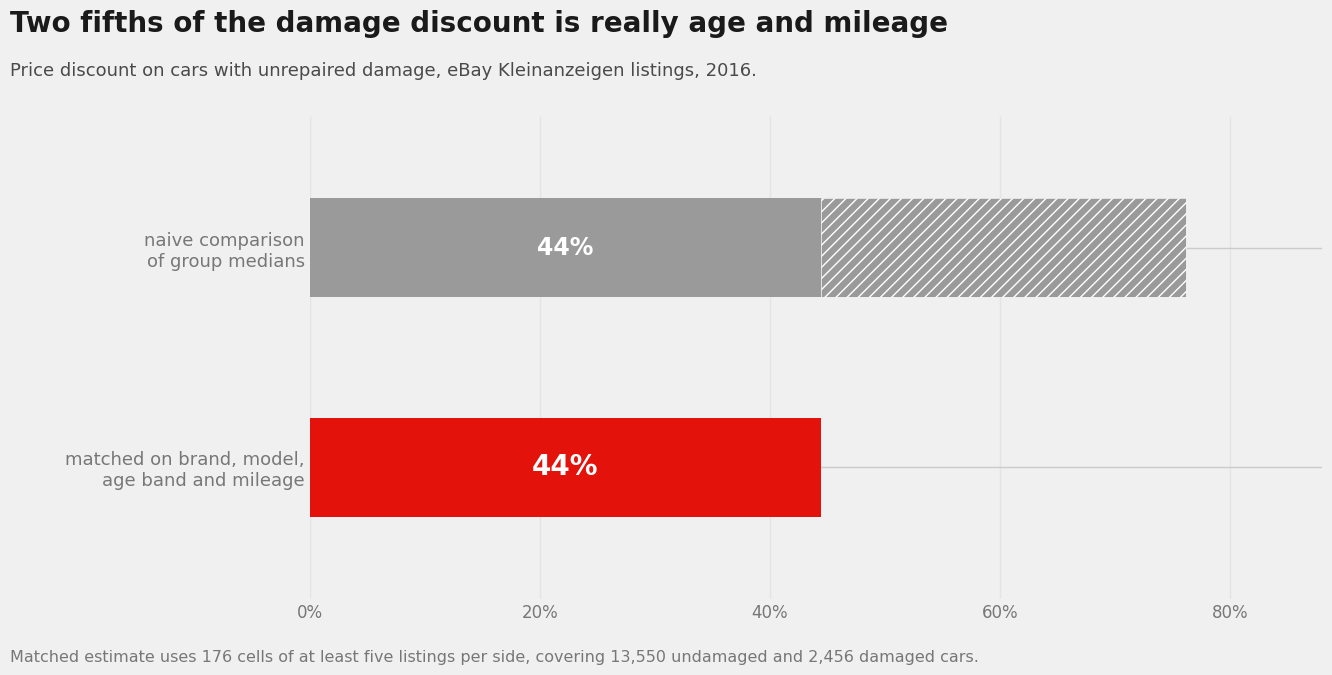

In [9]:
plt.style.use("fivethirtyeight")
C_NAIVE = "#9a9a9a"
C_REAL = "#e3120b"
C_BLUE = "#2e86ab"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: how much of the naive discount is confounding
weighted = np.average(cells["discount_pct"], weights=cells["n_damaged"])
naive = 100 * (1 - dd["price_eur"].median() / nd["price_eur"].median())

fig, ax = plt.subplots(figsize=(13.5, 7))
ax.barh([1], [naive], color=C_NAIVE, height=0.45, zorder=3)
ax.barh([0], [weighted], color=C_REAL, height=0.45, zorder=3)
ax.barh([1], [naive - weighted], left=[weighted], color=C_NAIVE, height=0.45, zorder=4,
        hatch="///", edgecolor="white")

ax.text(weighted / 2, 0, "%.0f%%" % weighted, ha="center", va="center",
        fontsize=20, weight="bold", color="white")
ax.text(weighted / 2, 1, "%.0f%%" % weighted, ha="center", va="center",
        fontsize=17, weight="bold", color="white")
ax.text(weighted + (naive - weighted) / 2, 1, "%.0f pts\nconfounding" % (naive - weighted),
        ha="center", va="center", fontsize=13, weight="bold", color="#3c3c3c")

ax.set_yticks([0, 1])
ax.set_yticklabels(["matched on brand, model,\nage band and mileage",
                    "naive comparison\nof group medians"], fontsize=13)
ax.set_xlim(0, 88)
ax.set_xticks([0, 20, 40, 60, 80])
ax.set_xticklabels(["0%", "20%", "40%", "60%", "80%"], fontsize=12)
ax.set_ylim(-0.6, 1.6)
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

fig.subplots_adjust(left=0.235, right=0.985, top=0.805, bottom=0.115)
fig.text(0.013, 0.925, "Two fifths of the damage discount is really age and mileage",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Price discount on cars with unrepaired damage, eBay Kleinanzeigen listings, 2016.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.025,
         "Matched estimate uses 176 cells of at least five listings per side, covering 13,550 undamaged and 2,456 damaged cars.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds

all charts within bounds: True


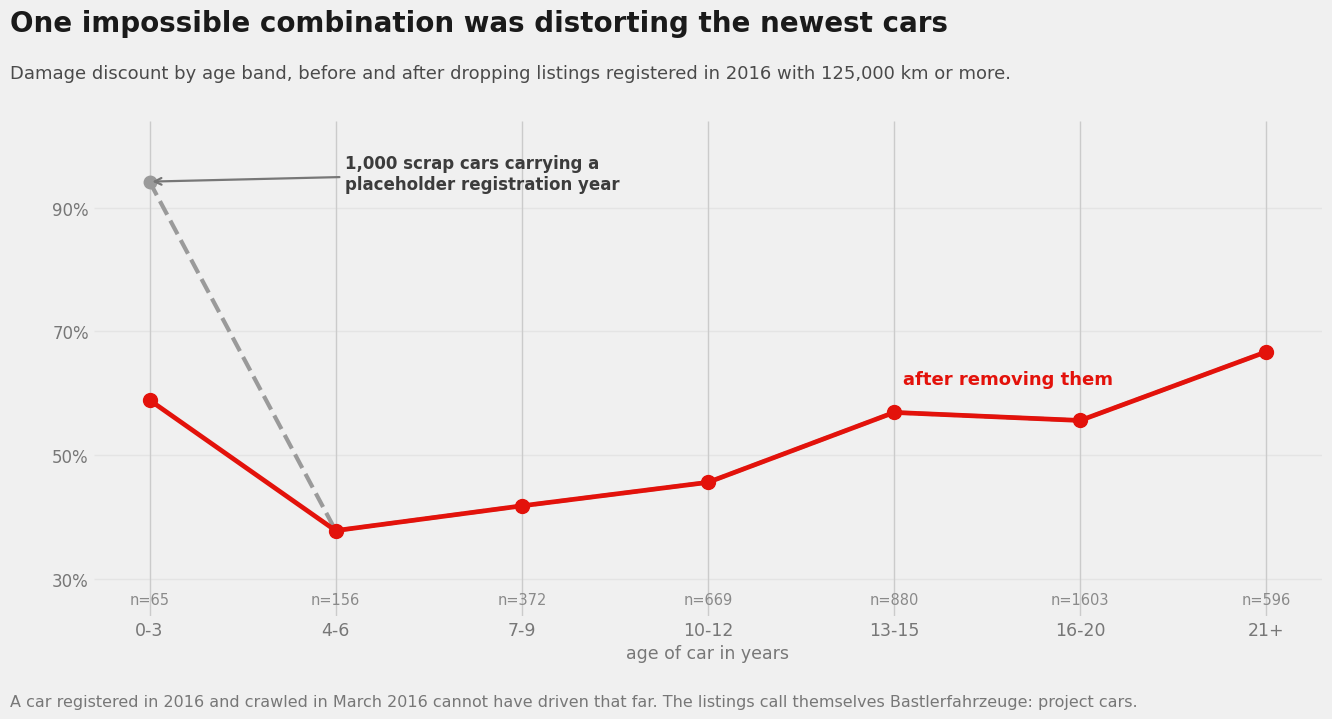

In [10]:
# Chart 2: what the impossible listings were doing to the age profile
x = np.arange(len(second_pass))
fig, ax = plt.subplots(figsize=(13.5, 7.5))

first_lookup = dict(zip(first_pass["age_band"].astype(str), first_pass["discount_pct"]))
before = [first_lookup[b] for b in second_pass["age_band"].astype(str)]

ax.plot(x, before, color=C_NAIVE, linewidth=3, marker="o", markersize=9,
        linestyle="--", zorder=3)
ax.plot(x, second_pass["discount_pct"], color=C_REAL, linewidth=3.4, marker="o",
        markersize=10, zorder=4)

for xi, v in zip(x, second_pass["n_damaged"]):
    ax.text(xi, 26, "n=%d" % v, ha="center", fontsize=10.5, color="#8a8a8a")

ax.set_xticks(x)
ax.set_xticklabels(second_pass["age_band"].astype(str), fontsize=12.5)
ax.set_ylim(24, 104)
ax.set_yticks([30, 50, 70, 90])
ax.set_yticklabels(["30%", "50%", "70%", "90%"], fontsize=12)
ax.set_xlabel("age of car in years", fontsize=12.5, color="#777777")
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3, axis="y")
for s in ax.spines.values():
    s.set_visible(False)

ax.annotate("1,000 scrap cars carrying a\nplaceholder registration year", xy=(0, 94.2),
            xytext=(1.05, 93), fontsize=12, color="#3c3c3c", weight="bold",
            arrowprops=dict(arrowstyle="->", color="#777777", linewidth=1.6))
ax.text(4.05, 61.5, "after removing them", color=C_REAL, fontsize=13, weight="bold")

fig.subplots_adjust(left=0.075, right=0.985, top=0.805, bottom=0.145)
fig.text(0.013, 0.925, "One impossible combination was distorting the newest cars",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Damage discount by age band, before and after dropping listings registered in 2016 with 125,000 km or more.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.025,
         "A car registered in 2016 and crawled in March 2016 cannot have driven that far. The listings call themselves Bastlerfahrzeuge: project cars.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
print()
print("all charts within bounds:", bool(ok1 and ok2))
plt.show()

## 7. Conclusions

### The answer

**Cars with unrepaired damage sell for about 44% less than comparable undamaged cars, not the 76% a direct comparison suggests.**

| Estimate | Discount |
|---|---|
| Naive comparison of group medians | 76.2% |
| Matched on brand, model, age band and mileage | **44.4%** |
| Interquartile range across 176 matched cells | 33.3% to 52.9% |

About **32 percentage points**, two fifths of the apparent effect, was age and mileage being charged to damage. Damaged cars in this data average 15.0 years old against 12.3 for undamaged, and 77% of them sit on the mileage cap against 60%.

### 1,000 physically impossible listings

A first pass by age band returned a 94.2% discount for cars aged 0 to 3, which is not a market price. The 200 listings behind it turned out to be scrap: **152 of them claimed a 2016 registration, and 131 sat at the 150,000 km cap**, in data crawled in March 2016. Their titles say so plainly, *Bastlerfahrzeug* (project car), *zum Ausschlachten* (for stripping), *springt nicht an* (will not start), and one offers a "Golf 2", a model built between 1983 and 1992.

Sellers who left the registration year blank appear to have been defaulted to **2016**, which the data then reads as brand new.

The filter needs no judgement about listing text: a car registered in 2016 and crawled in March 2016 cannot have driven 125,000 km. That combination covers **1,000 listings** with a median price of EUR 999, and removing them moves the 0 to 3 band from 94.2% to a plausible 58.9%.

### Other data quality findings

- **`seller`, `offerType` and `nrOfPictures` carry no information.** 49,999 of 50,000 listings are `privat` and `Angebot`; every single row has zero pictures. Scraping artifacts, not variables.
- **Prices include 1,421 zeros and values up to 99,999,999,** among them 11111111 and 12345678. Keyboard mashing, not prices.
- **Registration years run from 1000 to 9999,** with 1,966 listings registered after the crawl date.
- **Odometer is banded into 13 values and top-coded at 150,000 km,** where 65% of listings sit. Mileage cannot be controlled finely at the top of the range, which limits how well any matching can work.
- **19.7% of damage fields are blank,** and those listings look like damaged cars on age and mileage, not like a random sample. The blank rate rises to 48% among the impossible listings.

### What I would not claim

- **These are asking prices, not sale prices.** Nothing here shows what any car sold for, or whether it sold at all. A seller asking 44% less may still be asking too much.
- **Matching is not causal identification.** Cells match on brand, model, age band and mileage, but not on condition, service history, trim, engine, or how bad the damage is. "Unrepaired damage" covers a scratched bumper and a bent chassis alike.
- **The matched sample is not the whole market.** Requiring five listings per side keeps 176 cells covering 2,456 damaged cars, about half of them. Cells that qualify are the common models, so the estimate is weighted toward mass-market cars.
- **Excluding the blanks is a choice.** The sensitivity check brackets the naive discount between 67.8% and 71.4% depending on how they are treated, so the choice is not load-bearing, but it is a choice.
- **The 2016 and 125,000 km filter may catch some genuine listings,** such as an imported car registered in Germany in 2016 after years abroad. At 1,000 listings out of 46,315 the cost of over-filtering is small against the distortion of leaving them in.

---

*Dataset: eBay Kleinanzeigen used car listings, crawled March to April 2016, via the Dataquest version of the Kaggle dataset.*